## SVM i techniki resamplingu

Dane: zbiór pacjentów z poprzednich zajęć (612 obserwacji, zmienna wynikowa `stroke`: 1 – udar, 0 – brak udaru).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import confusion_matrix

dane = pd.read_csv("stroke_zaj1.csv", decimal=",", sep=";")
print(dane.shape)
print(dane["stroke"].value_counts())

(612, 11)
stroke
0    403
1    209
Name: count, dtype: int64


## Przygotowanie danych

Kroki zapisane są jako funkcja, ponieważ w zadaniu 3 (symulacja) trzeba je powtórzyć dla wielu zbiorów danych.

In [2]:
def przygotuj_dane(dane, seed=42):
    X = dane.drop(columns="stroke")
    y = dane["stroke"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed
    )
    X_train, X_test = X_train.copy(), X_test.copy()

    # Zmienne liczbowe: mediana ze zbioru uczącego
    kolumny_liczbowe = X.select_dtypes(include=np.number).columns
    imputer = SimpleImputer(strategy="median").fit(X_train[kolumny_liczbowe])
    X_train[kolumny_liczbowe] = imputer.transform(X_train[kolumny_liczbowe])
    X_test[kolumny_liczbowe] = imputer.transform(X_test[kolumny_liczbowe])

    # Zmienne kategoryczne: uzupełnianie proporcjonalne (proporcje ze zbioru uczącego)
    rng = np.random.default_rng(seed)
    for kolumna in X.select_dtypes(exclude=np.number).columns:
        proporcje = X_train[kolumna].value_counts(normalize=True)
        for zbior in (X_train, X_test):
            braki = zbior[kolumna].isna()
            zbior.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

    # Kodowanie zmiennych kategorycznych
    for zbior in (X_train, X_test):
        zbior["gender"] = zbior["gender"].map({"Male": 1, "Female": 0})
        zbior["ever_married"] = zbior["ever_married"].map({"Yes": 1, "No": 0})
    kolumny_dummy = ["work_type", "Residence_type", "smoking_status"]
    X_train = pd.get_dummies(X_train, columns=kolumny_dummy, dtype=int)
    X_test = pd.get_dummies(X_test, columns=kolumny_dummy, dtype=int).reindex(columns=X_train.columns, fill_value=0)

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = przygotuj_dane(dane)

print("Zbiór uczący:", X_train.shape, "| zbiór testowy:", X_test.shape)
print("Braki danych:", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("Udział klasy 1 – uczący: %.3f, testowy: %.3f" % (y_train.mean(), y_test.mean()))

Zbiór uczący: (489, 17) | zbiór testowy: (123, 17)
Braki danych: 0 0
Udział klasy 1 – uczący: 0.342, testowy: 0.341


### Funkcje pomocnicze

In [3]:
MIARY = ["dokladnosc", "czulosc", "specyficznosc"]
ETYKIETY = ["Dokładność", "Czułość", "Specyficzność"]
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def oblicz_miary(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "dokladnosc": (tp + tn) / (tn + fp + fn + tp),
        "czulosc": tp / (tp + fn),
        "specyficznosc": tn / (tn + fp),
    }


def ocen_model(model):
    return pd.DataFrame({
        "uczący": oblicz_miary(y_train, model.predict(X_train)),
        "testowy": oblicz_miary(y_test, model.predict(X_test)),
    }).T.round(3)


def macierze_pomylek(model, tytul):
    fig, osie = plt.subplots(1, 2, figsize=(9, 3.5))
    for os_, (nazwa, X_, y_) in zip(osie, [("uczący", X_train, y_train), ("testowy", X_test, y_test)]):
        sns.heatmap(confusion_matrix(y_, model.predict(X_)), annot=True, fmt="d", cmap="Blues", ax=os_,
                    xticklabels=["brak udaru", "udar"], yticklabels=["brak udaru", "udar"])
        os_.set_title(f"Zbiór {nazwa}")
        os_.set_xlabel("Przewidywana klasa")
        os_.set_ylabel("Rzeczywista klasa")
    fig.suptitle(tytul)
    plt.tight_layout()
    plt.show()

# SVM ze standaryzacją w pipeline, dopasowanie tylko do danych uczących.
def model_svm(**parametry):
    return Pipeline([("scaler", StandardScaler()), ("svm", SVC(**parametry))])


def badaj_parametr(budowa_modelu, wartosci, nazwa):
    wiersze = []
    for wartosc in wartosci:
        model = budowa_modelu(wartosc).fit(X_train, y_train)
        for zbior, X_, y_ in [("uczący", X_train, y_train), ("testowy", X_test, y_test)]:
            wiersze.append({nazwa: str(wartosc), "zbior": zbior, **oblicz_miary(y_, model.predict(X_))})
    wyniki = pd.DataFrame(wiersze)
    wyniki[nazwa] = pd.Categorical(wyniki[nazwa], categories=[str(w) for w in wartosci], ordered=True)
    return wyniki


def wykres(wyniki, nazwa, tytul):
    fig, osie = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for os_, miara, etykieta in zip(osie, MIARY, ETYKIETY):
        for zbior, styl in [("uczący", "-"), ("testowy", "--")]:
            d = wyniki[wyniki["zbior"] == zbior]
            os_.plot(d[nazwa].astype(str), d[miara], styl, marker="o", label=zbior)
        os_.set_title(etykieta)
        os_.set_xlabel(nazwa)
        os_.grid(alpha=0.3)
    osie[0].legend()
    fig.suptitle(tytul)
    plt.tight_layout()
    plt.show()

## Zadanie 1. Algorytm SVM

### a) Jądro liniowe

In [4]:
svm_liniowy = model_svm(kernel="linear").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_liniowy.named_steps["svm"].n_support_)
ocen_model(svm_liniowy)

Liczba wektorów nośnych (klasa 0, klasa 1): [127 126]


,dokladnosc,czulosc,specyficznosc
uczący,0.785,0.671,0.845
testowy,0.715,0.619,0.765


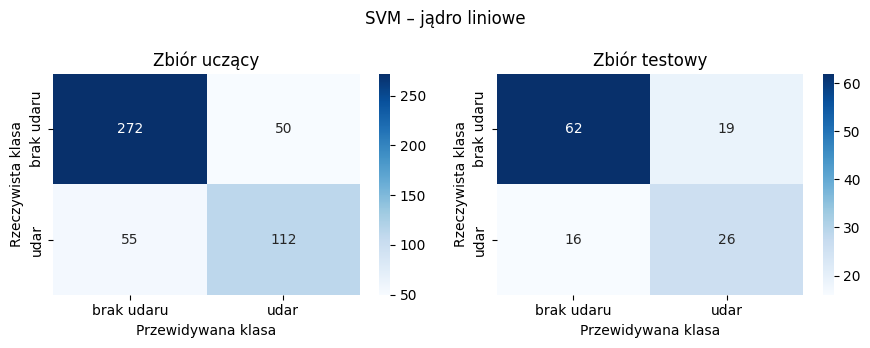

In [5]:
macierze_pomylek(svm_liniowy, "SVM – jądro liniowe")

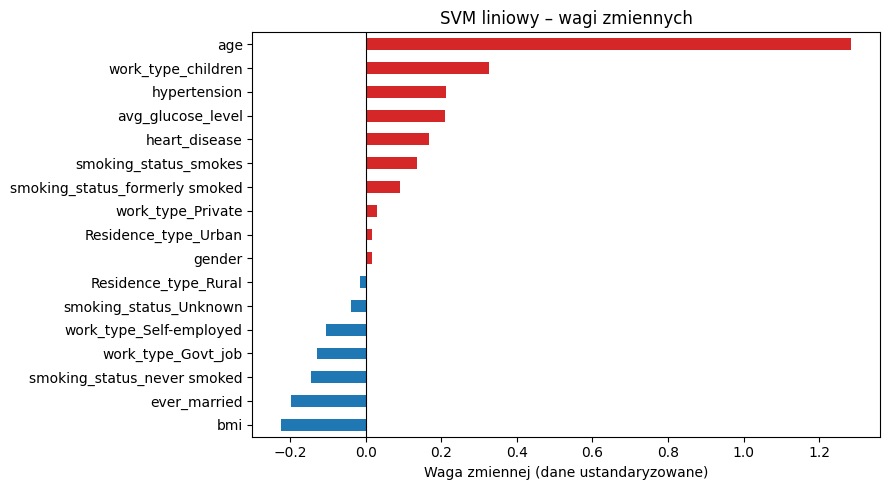

In [6]:
wagi = pd.Series(svm_liniowy.named_steps["svm"].coef_[0], index=X_train.columns).sort_values()

plt.figure(figsize=(9, 5))
wagi.plot(kind="barh", color=np.where(wagi > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Waga zmiennej (dane ustandaryzowane)")
plt.title("SVM liniowy – wagi zmiennych")
plt.tight_layout()
plt.show()

In [7]:
# Błędy na zbiorze testowym, wektory nośne i wagi zmiennych (SVM liniowy)
tn, fp, fn, tp = confusion_matrix(y_test, svm_liniowy.predict(X_test)).ravel()
print(f"Udar: przeoczone {fn} z {fn + tp} ({fn / (fn + tp):.1%})")
print(f"Brak udaru: błędnie wskazane {fp} z {fp + tn} ({fp / (fp + tn):.1%})")
liczba_wn = svm_liniowy.named_steps["svm"].n_support_.sum()
print(f"Wektory nośne: {liczba_wn} z {len(X_train)} ({liczba_wn / len(X_train):.1%})")
wagi.sort_values(ascending=False).round(3)

Udar: przeoczone 16 z 42 (38.1%)
Brak udaru: błędnie wskazane 19 z 81 (23.5%)
Wektory nośne: 253 z 489 (51.7%)


age                               1.286
work_type_children                0.327
hypertension                      0.213
avg_glucose_level                 0.211
heart_disease                     0.167
smoking_status_smokes             0.135
smoking_status_formerly smoked    0.089
work_type_Private                 0.028
Residence_type_Urban              0.017
gender                            0.015
Residence_type_Rural             -0.017
smoking_status_Unknown           -0.039
work_type_Self-employed          -0.106
work_type_Govt_job               -0.129
smoking_status_never smoked      -0.146
ever_married                     -0.198
bmi                              -0.225
dtype: float64

SVM z jądrem liniowym uzyskuje na zbiorze testowym dokładność 0,715, czułość 0,619 i specyficzność 0,765. Różnica względem zbioru uczącego (dokładność 0,785) wynosi ok. 7 p.p., więc model nie jest silnie przeuczony. Odsetek błędów jest większy wśród pacjentów z udarem (16 z 42, ok. 38%) niż wśród pacjentów bez udaru (19 z 81, ok. 23%). Model ma 253 wektory nośne (ok. 52% obserwacji uczących), czyli ponad połowa obserwacji leży na brzegu marginesu, wewnątrz niego lub po złej stronie granicy, co wskazuje, że klasy mocno na siebie nachodzą. Zdecydowanie największą wagę ma wiek (1,286), podobnie jak na poprzednich zajęciach. Wagi pozostałych zmiennych są małe i nie należy ich interpretować jako wpływu poszczególnych cech, ponieważ zmienne zero-jedynkowe jednej kategorii są ze sobą powiązane.

### b) Jądro wielomianowe

In [8]:
svm_wielomianowy = model_svm(kernel="poly").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_wielomianowy.named_steps["svm"].n_support_)
ocen_model(svm_wielomianowy)

Liczba wektorów nośnych (klasa 0, klasa 1): [169 149]


,dokladnosc,czulosc,specyficznosc
uczący,0.818,0.533,0.966
testowy,0.707,0.381,0.877


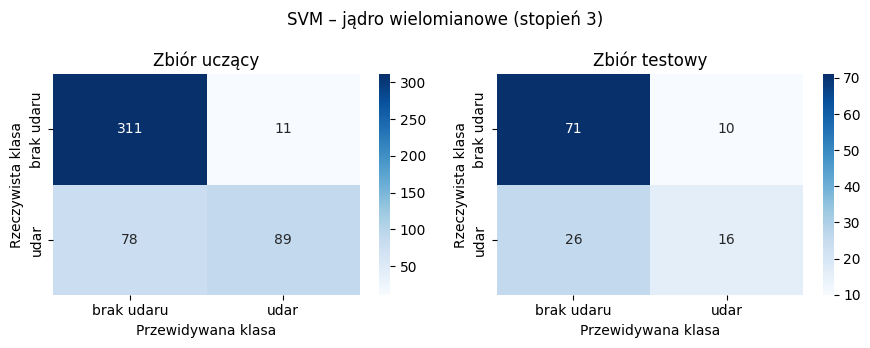

In [9]:
macierze_pomylek(svm_wielomianowy, "SVM – jądro wielomianowe (stopień 3)")

In [11]:
# Punkt odniesienia: model, który zawsze przewiduje „brak udaru”
print("Udział klasy 0 w zbiorze testowym:", round((y_test == 0).mean(), 3))

# Wartość gamma='scale' = 1 / (liczba zmiennych * wariancja danych po standaryzacji)
X_std = StandardScaler().fit_transform(X_train)
print("gamma='scale':", round(1 / (X_std.shape[1] * X_std.var()), 3))

Udział klasy 0 w zbiorze testowym: 0.659
gamma='scale': 0.059


Jądro wielomianowe (stopień 3, `coef0=0`) wypada najsłabiej: czułość na zbiorze testowym wynosi tylko 0,381, przy specyficzności 0,877. Model w większości przypadków przewiduje „brak udaru”, a jego dokładność (0,707) jest niewiele wyższa niż modelu przewidującego zawsze klasę większościową (0,659). Czułość jest niska również na zbiorze uczącym (0,533), więc problemem nie jest tylko przeuczenie, ale kształt granicy decyzyjnej. Możliwe wyjaśnienie: przy `coef0=0` jądro zawiera tylko składniki trzeciego stopnia, bez składników liniowych, a zależność w tych danych jest w dużej mierze liniowa.

### c) Jądro radialne (RBF)

In [12]:
svm_rbf = model_svm(kernel="rbf").fit(X_train, y_train)
print("Liczba wektorów nośnych (klasa 0, klasa 1):", svm_rbf.named_steps["svm"].n_support_)
ocen_model(svm_rbf)

Liczba wektorów nośnych (klasa 0, klasa 1): [162 149]


,dokladnosc,czulosc,specyficznosc
uczący,0.847,0.731,0.907
testowy,0.724,0.595,0.790


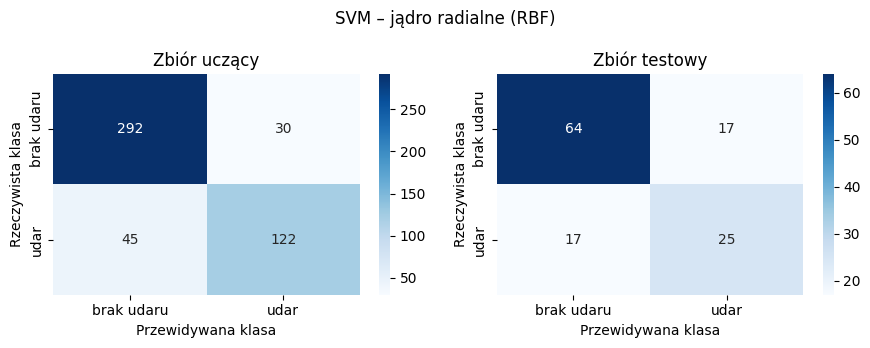

In [13]:
macierze_pomylek(svm_rbf, "SVM – jądro radialne (RBF)")

In [14]:
# Liczba poprawnych klasyfikacji na zbiorze testowym
for nazwa, model in [("liniowe", svm_liniowy), ("wielomianowe", svm_wielomianowy), ("rbf", svm_rbf)]:
    print(f"{nazwa}: {(model.predict(X_test) == y_test).sum()} z {len(y_test)}")

liniowe: 88 z 123
wielomianowe: 87 z 123
rbf: 89 z 123


Jądro radialne ma najwyższą dokładność na zbiorze testowym (0,724), z czułością 0,595 i specyficznością 0,790. Ma jednak największą różnicę między zbiorem uczącym i testowym (dokładność 0,847 wobec 0,724), czyli najsilniej się przeucza. Elastyczna, nieliniowa granica lepiej dopasowuje się do zbioru uczącego, ale na zbiorze testowym przewaga nad modelem liniowym to tylko jedna obserwacja (89 wobec 88 poprawnych klasyfikacji).

### Porównanie jąder i wybór najlepszego modelu

Najlepszy model jest wybrany na podstawie 5-krotnej walidacji krzyżowej na zbiorze uczącym (kryterium: *balanced accuracy*, czyli średnia czułości i specyficzności), a nie na podstawie zbioru testowego.

In [13]:
jadra = {"linear": svm_liniowy, "poly": svm_wielomianowy, "rbf": svm_rbf}

porownanie_jader = pd.DataFrame({
    jadro: {
        **{f"test_{m}": v for m, v in oblicz_miary(y_test, model.predict(X_test)).items()},
        "CV_balanced_accuracy": cross_val_score(model_svm(kernel=jadro), X_train, y_train,
                                                cv=kfold, scoring="balanced_accuracy").mean(),
        "wektory_nosne": model.named_steps["svm"].n_support_.sum(),
    }
    for jadro, model in jadra.items()
}).T

najlepsze_jadro = porownanie_jader["CV_balanced_accuracy"].astype(float).idxmax()
print("Najlepsze jądro wg walidacji krzyżowej:", najlepsze_jadro)
porownanie_jader.round(3)

Najlepsze jądro wg walidacji krzyżowej: linear


,test_dokladnosc,test_czulosc,test_specyficznosc,CV_balanced_accuracy,wektory_nosne
linear,0.715,0.619,0.765,0.725,253.0
poly,0.707,0.381,0.877,0.604,318.0
rbf,0.724,0.595,0.790,0.674,311.0


### d) Wpływ hiperparametrów najlepszego modelu

Dla jądra liniowego najważniejszym hiperparametrem jest `C`, czyli kara za błędną klasyfikację:
- **małe `C`**: szeroki margines, model toleruje wiele błędów na zbiorze uczącym (prostszy model, ryzyko niedouczenia),
- **duże `C`**: wąski margines, model stara się poprawnie sklasyfikować jak najwięcej obserwacji uczących (ryzyko przeuczenia).

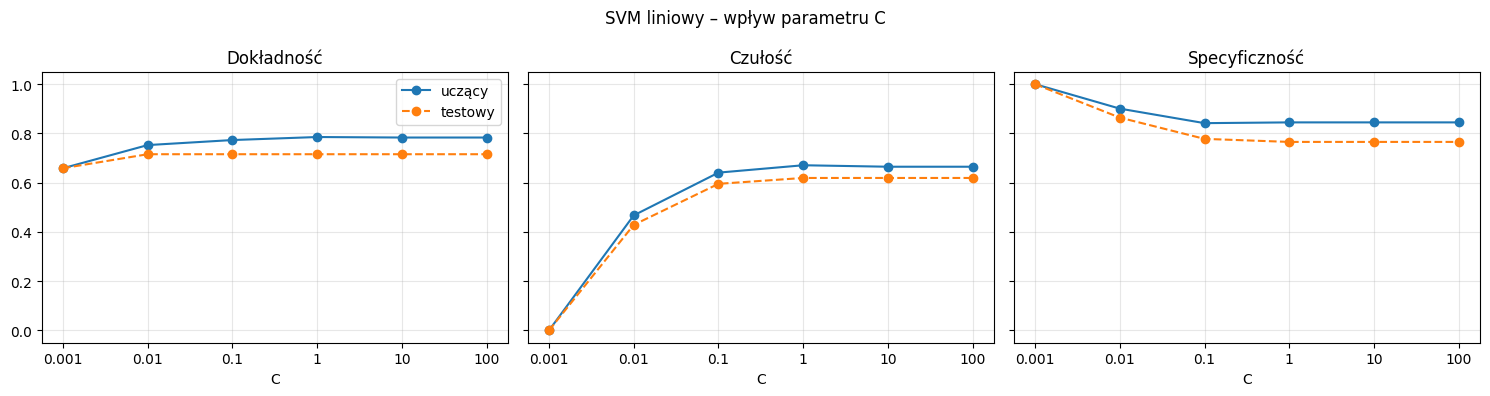

dokladnosc        czulosc        specyficznosc       
zbior    testowy uczący testowy uczący       testowy uczący
C                                                          
0.001      0.659  0.658   0.000  0.000         1.000  1.000
0.01       0.715  0.753   0.429  0.467         0.864  0.901
0.1        0.715  0.773   0.595  0.641         0.778  0.842
1          0.715  0.785   0.619  0.671         0.765  0.845
10         0.715  0.783   0.619  0.665         0.765  0.845
100        0.715  0.783   0.619  0.665         0.765  0.845

In [15]:
wartosci_C = [0.001, 0.01, 0.1, 1, 10, 100]

wyniki_C = badaj_parametr(lambda c: model_svm(kernel="linear", C=c), wartosci_C, "C")
wykres(wyniki_C, "C", "SVM liniowy – wpływ parametru C")
wyniki_C.pivot(index="C", columns="zbior", values=MIARY).round(3)

In [16]:
cv_C = pd.Series({
    str(c): cross_val_score(model_svm(kernel="linear", C=c), X_train, y_train,
                            cv=kfold, scoring="balanced_accuracy").mean()
    for c in wartosci_C
}, name="CV balanced accuracy")

najlepsze_C = float(cv_C.idxmax())
print("Najlepsze C wg walidacji krzyżowej:", najlepsze_C)
cv_C.round(3)

Najlepsze C wg walidacji krzyżowej: 10.0


0.001    0.500
0.01     0.661
0.1      0.729
1        0.725
10       0.732
100      0.732
Name: CV balanced accuracy, dtype: float64

Przy bardzo małym `C` (0,001) kara za błędy jest tak mała, że model zawsze przewiduje „brak udaru” (czułość 0, a dokładność 0,659 jest równa udziałowi klasy 0). Zwiększanie `C` podnosi czułość kosztem specyficzności, ale od `C=1` wyniki praktycznie się nie zmieniają. Różnica między zbiorem uczącym i testowym nie przekracza 7 p.p., więc przeuczenie nie narasta nawet przy słabej regularyzacji. Walidacja krzyżowa wskazała `C=10` (balanced accuracy 0,732), ale wyniki dla `C` od 0,1 do 100 różnią się o mniej niż 0,01. Dokładność na zbiorze testowym wynosi 0,715 dla wszystkich `C` od 0,01 do 100, mimo zmian czułości i specyficzności, co pokazuje, że sama dokładność nie wystarcza do oceny modelu.

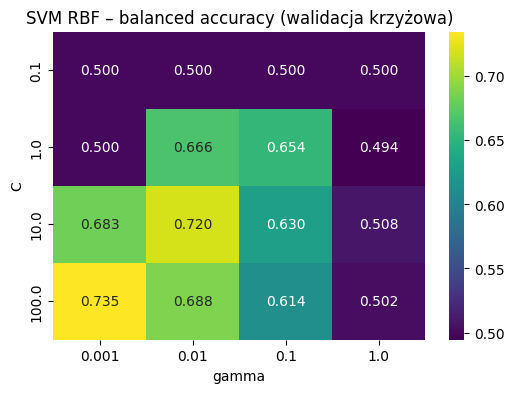

In [18]:
siatka_C = [0.1, 1, 10, 100]
siatka_gamma = [0.001, 0.01, 0.1, 1]

siatka = pd.DataFrame(
    [[cross_val_score(model_svm(kernel="rbf", C=c, gamma=g), X_train, y_train,
                      cv=kfold, scoring="balanced_accuracy").mean()
      for g in siatka_gamma] for c in siatka_C],
    index=pd.Index(siatka_C, name="C"), columns=pd.Index(siatka_gamma, name="gamma"),
)

plt.figure(figsize=(6, 4))
sns.heatmap(siatka, annot=True, fmt=".3f", cmap="viridis")
plt.title("SVM RBF – balanced accuracy (walidacja krzyżowa)")
plt.show()

In [19]:
from sklearn.model_selection import cross_val_predict

# Skrajne i najlepsze ustawienia z siatki RBF
wiersze_rbf = []
for c, gm in [(0.1, 0.001), (0.1, 1), (1, 1), (10, 1), (100, 1), (100, 0.001)]:
    model = model_svm(kernel="rbf", C=c, gamma=gm)
    pred_cv = cross_val_predict(model, X_train, y_train, cv=kfold)
    model.fit(X_train, y_train)
    wiersze_rbf.append({
        "C": c, "gamma": gm,
        "CV_udzial_przewidzianych_udarow": pred_cv.mean(),
        "uczacy_dokladnosc": (model.predict(X_train) == y_train).mean(),
        **{f"test_{m}": v for m, v in oblicz_miary(y_test, model.predict(X_test)).items()},
    })
pd.DataFrame(wiersze_rbf).round(3)

,C,gamma,CV_udzial_przewidzianych_udarow,uczacy_dokladnosc,test_dokladnosc,test_czulosc,test_specyficznosc
0,0.1,0.001,0.000,0.658,0.659,0.000,1.000
1,0.1,1.000,0.000,0.658,0.659,0.000,1.000
2,1.0,1.000,0.067,0.947,0.642,0.095,0.926
3,10.0,1.000,0.133,0.990,0.577,0.190,0.778
4,100.0,1.000,0.135,0.998,0.569,0.190,0.765
5,100.0,0.001,0.325,0.793,0.715,0.619,0.765


Dla jądra radialnego przeszukana została siatka `C` i `gamma` (`gamma` określa zasięg wpływu pojedynczej obserwacji). Przy `C=0,1` model nie przewiduje żadnego udaru z powodu zbyt silnej regularyzacji. Przy `gamma=1` i `C ≥ 1` model dopasowuje się do pojedynczych obserwacji (dokładność na zbiorze uczącym ok. 0,95–1,00), a na nowych danych przewiduje głównie klasę 0. Najlepszy wynik (0,735 dla `C=100`, `gamma=0,001`) jest praktycznie taki sam jak dla jądra liniowego, a na zbiorze testowym wyniki obu modeli są identyczne. Jest to zgodne z teorią: przy małym `gamma` i dużym `C` SVM z jądrem RBF zbliża się do SVM liniowego. Dlatego jako model końcowy pozostawiony został prostszy model liniowy.

### Model końcowy z zadania 1

In [17]:
svm_najlepszy = model_svm(kernel="linear", C=najlepsze_C).fit(X_train, y_train)
ocen_model(svm_najlepszy)

,dokladnosc,czulosc,specyficznosc
uczący,0.783,0.665,0.845
testowy,0.715,0.619,0.765


Model końcowy (jądro liniowe, `C=10`) daje na zbiorze testowym te same wyniki co model z domyślnym `C`: dokładność 0,715, czułość 0,619 i specyficzność 0,765. Ok. 38% przypadków udaru pozostaje niewykrytych, co częściowo wynika z przewagi klasy 0 w zbiorze uczącym (zadanie 2).

## Zadanie 2. Techniki resamplingu

### a) Wpływ resamplingu na wyniki modelu

In [20]:
# Zwraca indeksy klasy mniejszościowej i większościowej
def podziel_klasy(y):
    i0, i1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1)
    return (i1, i0) if len(i1) < len(i0) else (i0, i1)


# Losowanie ze zwracaniem obserwacji klasy mniejszościowej, aż obie klasy będą równe
def losowy_oversampling(X, y, rng):
    mniejsza, wieksza = podziel_klasy(y)
    dodatkowe = rng.choice(mniejsza, size=len(wieksza) - len(mniejsza), replace=True)
    indeksy = np.concatenate([wieksza, mniejsza, dodatkowe])
    return X[indeksy], y[indeksy]


# Losowanie bez zwracania tylu obserwacji klasy większościowej, ile jest w klasie mniejszościowej.
def losowy_undersampling(X, y, rng):
    mniejsza, wieksza = podziel_klasy(y)
    wybrane = rng.choice(wieksza, size=len(mniejsza), replace=False)
    indeksy = np.concatenate([wybrane, mniejsza])
    return X[indeksy], y[indeksy]


# SMOTE: nowa obserwacja = punkt klasy mniejszościowej + losowa część odcinka do jednego z k najbliższych sąsiadów z tej samej klasy.
def smote(X, y, rng, k=5):
    mniejsza, wieksza = podziel_klasy(y)
    X_min = X[mniejsza]
    ile_nowych = len(wieksza) - len(mniejsza)
    k = min(k, len(X_min) - 1)
    sasiedzi = NearestNeighbors(n_neighbors=k + 1).fit(X_min).kneighbors(X_min, return_distance=False)[:, 1:]

    punkt = rng.integers(0, len(X_min), ile_nowych)                    # losowy punkt klasy mniejszościowej
    sasiad = sasiedzi[punkt, rng.integers(0, k, ile_nowych)]           # losowy z jego k sąsiadów
    lam = rng.random((ile_nowych, 1))                                  # losowa liczba z przedziału [0, 1)
    nowe = X_min[punkt] + lam * (X_min[sasiad] - X_min[punkt])

    klasa_mniejsza = y[mniejsza[0]]
    return np.vstack([X, nowe]), np.concatenate([y, np.full(ile_nowych, klasa_mniejsza)])


METODY = {
    "brak": None,
    "oversampling": losowy_oversampling,
    "undersampling": losowy_undersampling,
    "SMOTE": smote,
}

In [21]:
def dopasuj(X_tr, y_tr, metoda, rng, wagi_klas=None):
    skaler = StandardScaler().fit(X_tr)
    X_s, y_s = skaler.transform(X_tr), np.asarray(y_tr)
    if METODY.get(metoda) is not None:
        X_s, y_s = METODY[metoda](X_s, y_s, rng)
    svm = SVC(kernel="linear", C=najlepsze_C, class_weight=wagi_klas).fit(X_s, y_s)
    return skaler, svm, y_s


# Liczebność klas po resamplingu (zbiór uczący)
liczebnosci = {}
for metoda in METODY:
    _, _, y_po = dopasuj(X_train, y_train, metoda, np.random.default_rng(42))
    liczebnosci[metoda] = np.bincount(y_po)
pd.DataFrame(liczebnosci, index=["klasa 0", "klasa 1"]).T

,klasa 0,klasa 1
brak,322,167
oversampling,322,322
undersampling,167,167
SMOTE,322,322


In [22]:
warianty = [(m, m, None) for m in METODY] + [("wagi klas", "brak", "balanced")]

wyniki_test, wyniki_cv = {}, {}
for nazwa, metoda, wagi_klas in warianty:
    # Zbiór testowy
    skaler, svm, _ = dopasuj(X_train, y_train, metoda, np.random.default_rng(42), wagi_klas)
    wyniki_test[nazwa] = oblicz_miary(y_test, svm.predict(skaler.transform(X_test)))

    # Walidacja krzyżowa: resampling osobno w każdym podziale, tylko na części uczącej
    miary_cv = []
    for nr, (i_ucz, i_wal) in enumerate(kfold.split(X_train, y_train)):
        skaler, svm, _ = dopasuj(X_train.iloc[i_ucz], y_train.iloc[i_ucz], metoda,
                                 np.random.default_rng(nr), wagi_klas)
        miary_cv.append(oblicz_miary(y_train.iloc[i_wal], svm.predict(skaler.transform(X_train.iloc[i_wal]))))
    wyniki_cv[nazwa] = pd.DataFrame(miary_cv).mean()

wyniki_test = pd.DataFrame(wyniki_test).T
wyniki_cv = pd.DataFrame(wyniki_cv).T

print("Zbiór testowy:")
print(wyniki_test.round(3))
print("\nŚrednia z 5-krotnej walidacji krzyżowej:")
print(wyniki_cv.round(3))

Zbiór testowy:
               dokladnosc  czulosc  specyficznosc
brak                0.715    0.619          0.765
oversampling        0.683    0.714          0.667
undersampling       0.675    0.714          0.654
SMOTE               0.691    0.690          0.691
wagi klas           0.715    0.738          0.704

Średnia z 5-krotnej walidacji krzyżowej:
               dokladnosc  czulosc  specyficznosc
brak                0.767    0.623          0.842
oversampling        0.751    0.760          0.745
undersampling       0.759    0.796          0.739
SMOTE               0.757    0.760          0.755
wagi klas           0.757    0.771          0.748


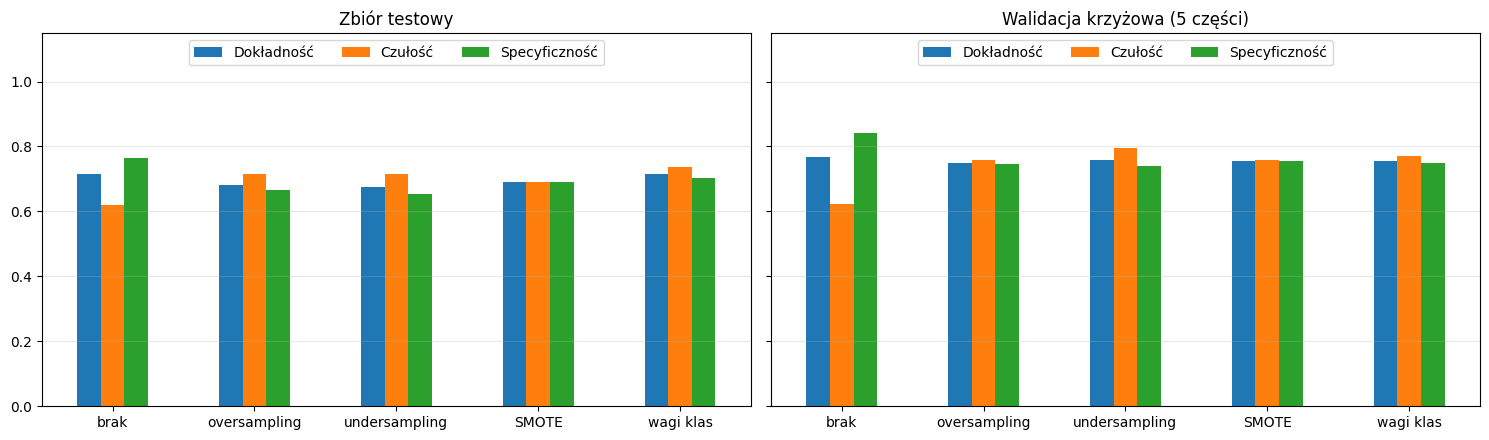

In [23]:
fig, osie = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for os_, (tytul, df) in zip(osie, [("Zbiór testowy", wyniki_test), ("Walidacja krzyżowa (5 części)", wyniki_cv)]):
    df.set_axis(ETYKIETY, axis=1).plot(kind="bar", ax=os_, rot=0)
    os_.set_title(tytul)
    os_.set_ylim(0, 1.15)
    os_.legend(loc="upper center", ncol=3)
    os_.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Balanced accuracy (średnia czułości i specyficzności) dla technik resamplingu
print("Wagi klas w trybie 'balanced' (klasa 0, klasa 1):", (len(y_train) / (2 * np.bincount(y_train))).round(3))
pd.DataFrame({
    "CV": (wyniki_cv["czulosc"] + wyniki_cv["specyficznosc"]) / 2,
    "testowy": (wyniki_test["czulosc"] + wyniki_test["specyficznosc"]) / 2,
}).round(3)

Wagi klas w trybie 'balanced' (klasa 0, klasa 1): [0.759 1.464]


,CV,testowy
brak,0.732,0.692
oversampling,0.753,0.690
undersampling,0.768,0.684
SMOTE,0.757,0.691
wagi klas,0.760,0.721


Wszystkie techniki resamplingu, podobnie jak wagi klas, zwiększają czułość kosztem specyficzności. W walidacji krzyżowej czułość rośnie z 0,623 do 0,760–0,796, a specyficzność spada z 0,842 do 0,739–0,755. Po wyrównaniu klas obie klasy mają łącznie taki sam wpływ na uczenie modelu, więc granica decyzyjna przesuwa się w stronę klasy 0. Balanced accuracy w walidacji krzyżowej rośnie z 0,732 do 0,753–0,768. Na zbiorze testowym czułość również rośnie, ale balanced accuracy poprawia się tylko dla wag klas (0,721 wobec 0,692). Undersampling daje najwyższą czułość (0,796), ale odrzuca 155 obserwacji klasy 0, a oversampling i SMOTE dają bardzo podobne wyniki. Przy predykcji udaru wyższa czułość jest zwykle korzystna, bo przeoczenie choroby jest poważniejszym błędem niż fałszywy alarm.

### b) Opis technik resamplingu

Resampling wyrównuje liczebność klas w zbiorze uczącym, aby model nie faworyzował klasy większościowej.
- **oversampling** losuje ze zwracaniem obserwacje klasy mniejszościowej i dodaje ich kopie (167 → 322). Nie traci informacji, ale powielanie tych samych obserwacji grozi przeuczeniem,
- **undersampling** losuje bez zwracania tyle obserwacji klasy większościowej, ile liczy klasa mniejszościowa, a resztę odrzuca (322 → 167). Jest prosty, ale traci część danych,
- **SMOTE** tworzy syntetyczne obserwacje: nowy punkt leży na odcinku między obserwacją klasy mniejszościowej a jednym z jej 5 najbliższych sąsiadów z tej samej klasy (x_new = x_i + λ·(x_zi − x_i), λ ∈ [0, 1]). Wymaga ustandaryzowanych danych, a dla zmiennych zero-jedynkowych tworzy wartości pośrednie (dla danych mieszanych istnieje wariant SMOTE-NC),
- **wagi klas** (`class_weight="balanced"`) nie zmieniają danych, tylko mnożą karę `C` przez 1,464 dla klasy 1 i przez 0,759 dla klasy 0.

Resampling stosowano wyłącznie na zbiorze uczącym (w walidacji krzyżowej w każdym podziale osobno), ponieważ wykonanie go przed podziałem danych powoduje wyciek informacji i zbyt optymistyczną ocenę modelu.

## Zadanie 3. Symulacja

Aby uzyskać zbiory o różnym stopniu niezbalansowania, pozostawione zostją wszystkie 403 obserwacje klasy 0 i losowana jest część obserwacji klasy 1, tak aby udział klasy pozytywnej wynosił 5%, 10%, 20% lub 34% (pełny zbiór).

Dla każdego udziału losowanie powtórzone jest 50 razy, ponieważ przy małym udziale w zbiorze testowym znajduje się tylko kilka przypadków udaru i wynik pojedynczego losowania byłby bardzo niestabilny. W każdym powtórzeniu następuje:
1. losowanie obserwacje klasy 1,
2. przygotowanie danych (podział, uzupełnienie braków, kodowanie) funkcją `przygotuj_dane`,
3. budowa SVM liniowego bez resamplingu i z każdą techniką resamplingu,
4. obliczenie miar na zbiorze testowym.

Na końcu uśrednienie wyników z 50 powtórzeń.

In [25]:
udzialy = [0.05, 0.10, 0.20, 0.34]
liczba_powtorzen = 50

negatywne = dane[dane["stroke"] == 0]
pozytywne = dane[dane["stroke"] == 1]

wyniki_symulacji = []
for udzial in udzialy:
    liczba_pozytywnych = round(udzial / (1 - udzial) * len(negatywne))
    for powtorzenie in range(liczba_powtorzen):
        probka = pd.concat([negatywne, pozytywne.sample(liczba_pozytywnych, random_state=powtorzenie)])
        X_tr, X_te, y_tr, y_te = przygotuj_dane(probka, seed=powtorzenie)
        for metoda in METODY:
            skaler, svm, _ = dopasuj(X_tr, y_tr, metoda, np.random.default_rng(powtorzenie))
            wyniki_symulacji.append({
                "udzial_klasy_1": udzial, "metoda": metoda, "powtorzenie": powtorzenie,
                "liczba_1_w_tescie": int(y_te.sum()),
                **oblicz_miary(y_te, svm.predict(skaler.transform(X_te))),
            })

wyniki_symulacji = pd.DataFrame(wyniki_symulacji)
print("Średnia liczba przypadków udaru w zbiorze testowym:")
print(wyniki_symulacji.groupby("udzial_klasy_1")["liczba_1_w_tescie"].mean())

Średnia liczba przypadków udaru w zbiorze testowym:
udzial_klasy_1
0.05     4.0
0.10     9.0
0.20    20.0
0.34    42.0
Name: liczba_1_w_tescie, dtype: float64


In [26]:
srednie = wyniki_symulacji.groupby(["udzial_klasy_1", "metoda"])[MIARY].mean()
srednie.unstack("metoda").reindex(columns=list(METODY), level="metoda").round(3)

dokladnosc                                   czulosc  \
metoda               brak oversampling undersampling  SMOTE    brak   
udzial_klasy_1                                                        
0.05                0.952        0.772         0.660  0.766   0.000   
0.10                0.895        0.737         0.696  0.741   0.002   
0.20                0.798        0.740         0.729  0.743   0.258   
0.34                0.760        0.749         0.747  0.745   0.638   

                                                 specyficznosc               \
metoda         oversampling undersampling  SMOTE          brak oversampling   
udzial_klasy_1                                                                
0.05                  0.550         0.620  0.505         1.000        0.783   
0.10                  0.716         0.702  0.711         0.994        0.740   
0.20                  0.732         0.740  0.714         0.931        0.742   
0.34                  0.762         0.775  0.769         0.823        0.742   

                                     
metoda         undersampling  SMOTE  
udzial_klasy_1                       
0.05                   0.662  0.779  
0.10                   0.696  0.744  
0.20                   0.726  0.750  
0.34                   0.732  0.733

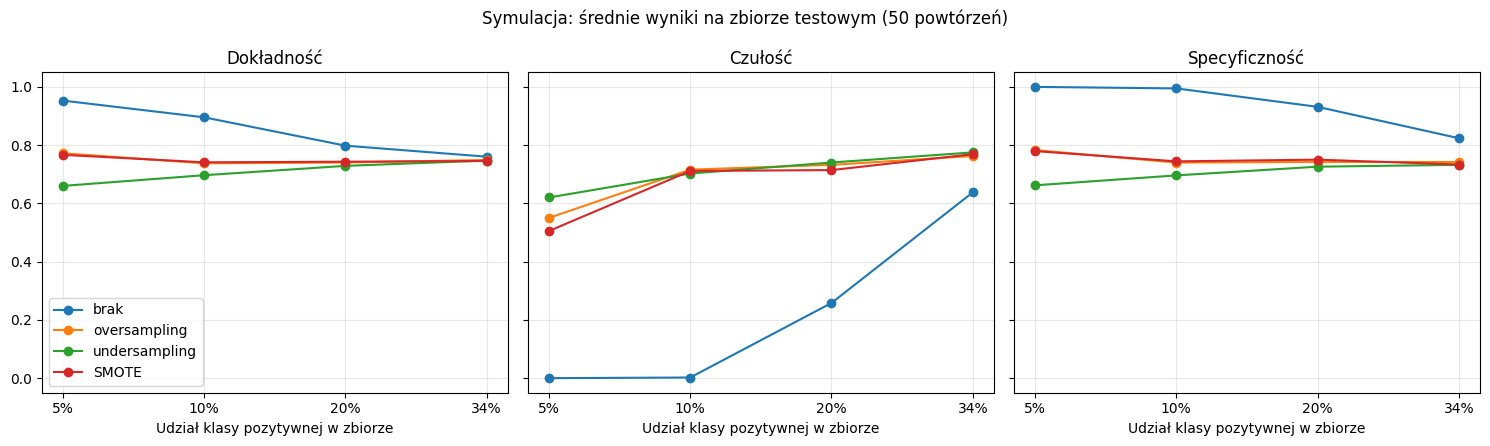

In [27]:
fig, osie = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for os_, miara, etykieta in zip(osie, MIARY, ETYKIETY):
    for metoda in METODY:
        d = srednie.xs(metoda, level="metoda")[miara]
        os_.plot([f"{u:.0%}" for u in d.index], d.values, marker="o", label=metoda)
    os_.set_title(etykieta)
    os_.set_xlabel("Udział klasy pozytywnej w zbiorze")
    os_.grid(alpha=0.3)
osie[0].legend()
fig.suptitle(f"Symulacja: średnie wyniki na zbiorze testowym ({liczba_powtorzen} powtórzeń)")
plt.tight_layout()
plt.show()

In [28]:
# Zmienność wyników: odchylenie standardowe czułości między powtórzeniami
wyniki_symulacji.groupby(["udzial_klasy_1", "metoda"])["czulosc"].std().unstack("metoda")[list(METODY)].round(3)

metoda,brak,oversampling,undersampling,SMOTE
udzial_klasy_1,,,,
0.05,0.000,0.281,0.254,0.274
0.10,0.016,0.147,0.158,0.157
0.20,0.119,0.091,0.099,0.098
0.34,0.060,0.052,0.061,0.055


In [29]:
# Liczebności w symulacji (nie zależą od losowania, bo podział jest warstwowy)
rozmiary = []
for udzial in udzialy:
    liczba_pozytywnych = round(udzial / (1 - udzial) * len(negatywne))
    probka = pd.concat([negatywne, pozytywne.sample(liczba_pozytywnych, random_state=0)])
    _, _, y_tr_, y_te_ = przygotuj_dane(probka, seed=0)
    rozmiary.append({
        "udzial_klasy_1": udzial,
        "obserwacje": len(probka),
        "udzial_klasy_0": (probka["stroke"] == 0).mean(),
        "uczacy": len(y_tr_),
        "udary_uczacy": int(y_tr_.sum()),
        "udary_test": int(y_te_.sum()),
        "uczacy_po_undersamplingu": 2 * int(y_tr_.sum()),
        "odrzucone_przy_undersamplingu": 1 - 2 * y_tr_.sum() / len(y_tr_),
    })
pd.DataFrame(rozmiary).round(3)

,udzial_klasy_1,obserwacje,udzial_klasy_0,uczacy,udary_uczacy,udary_test,uczacy_po_undersamplingu,odrzucone_przy_undersamplingu
0,0.05,424,0.95,339,17,4,34,0.900
1,0.10,448,0.90,358,36,9,72,0.799
2,0.20,504,0.80,403,81,20,162,0.598
3,0.34,611,0.66,488,166,42,332,0.320


Bez resamplingu przy udziale klasy pozytywnej 5% i 10% model praktycznie zawsze przewiduje „brak udaru” (czułość 0 i 0,002). Dokładność jest wtedy bardzo wysoka (0,952 i 0,895), ale wynika niemal wyłącznie z udziału klasy 0, co pokazuje, że przy silnym niezbalansowaniu sama dokładność jest myląca. Z resamplingiem już od udziału 10% czułość wynosi ok. 0,70–0,78, a specyficzność ok. 0,70–0,75. Przy 5% wszystkie techniki działają słabiej (czułość 0,505–0,620) i bardzo niestabilnie (odchylenie standardowe czułości 0,25–0,28), ponieważ w zbiorze uczącym jest tylko 17 przypadków udaru, a w testowym 4. Undersampling daje wtedy najwyższą czułość, ale najniższą specyficzność (0,662), bo uczy się tylko na 34 obserwacjach. Oversampling i SMOTE zachowują wszystkie obserwacje klasy 0, dzięki czemu mają wyższą specyficzność (ok. 0,78).

## Podsumowanie

- Najlepsze okazało się jądro liniowe. Jądro wielomianowe miało bardzo niską czułość, a radialne silniej się przeuczało i po dostrojeniu osiągnęło ten sam wynik co liniowe.
- Parametr `C` ma znaczenie tylko przy bardzo małych wartościach; od `C=0,1` wyniki praktycznie się nie zmieniają.
- SVM liniowy na zbiorze testowym (dokładność 0,715, czułość 0,619, specyficzność 0,765) wypada podobnie jak las losowy i AdaBoost z poprzednich zajęć, ale w walidacji krzyżowej nie przewyższa drzewa z jednym podziałem według wieku (balanced accuracy 0,732 wobec 0,775).
- Resampling i wagi klas zwiększają czułość kosztem specyficzności. Na pełnym zbiorze efekt jest umiarkowany, ale przy silnym niezbalansowaniu (5–10%) model bez resamplingu w ogóle nie wykrywa udaru, mimo dokładności powyżej 0,89.
- Undersampling daje zwykle najwyższą czułość, ale traci najwięcej danych, natomiast oversampling, SMOTE i wagi klas zachowują wszystkie obserwacje. Przy bardzo małej liczbie przypadków udaru (5%) żadna technika nie daje stabilnych wyników.

Wyniki są spójne z poprzednimi zajęciami: w tych danych większość informacji niesie wiek, a przy niezbalansowanych danych ocena modelu musi uwzględniać czułość i specyficzność, a nie tylko dokładność.